# Perform a time series decomposition of a dataset with seasonal and trend components. 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose


In [2]:
data = pd.read_csv("network_traffic.csv")

In [4]:
print(data.head())

       Time           Source  No.      Destination Protocol  Length  \
0  0.000000    192.167.8.166    1  192.167.255.255     NBNS      92   
1  0.784682    192.167.8.166    2  192.167.255.255     NBNS      92   
2  1.169060  VMware_8a:5c:e6    3        Broadcast      ARP      60   
3  2.167949  VMware_8a:5c:e6    4        Broadcast      ARP      60   
4  3.170095  VMware_8a:5c:e6    5        Broadcast      ARP      60   

                                      Info  
0                   Name query NB WPAD<00>  
1                   Name query NB WPAD<00>  
2  Who has 192.167.7.175? Tell 192.167.0.1  
3  Who has 192.167.7.175? Tell 192.167.0.1  
4  Who has 192.167.7.175? Tell 192.167.0.1  


Converting Time to Numeric

In [6]:
data["Time"] = pd.to_numeric(data["Time"], errors="coerce")

In [7]:
data.dropna(subset=["Time", "Length"], inplace=True)

Creating Timestamp

In [9]:
data["Timestamp"] = pd.to_datetime(data["Time"], unit="s")

In [10]:
data.set_index("Timestamp", inplace=True)

Creating Time Series

In [16]:
traffic = data["Length"].resample("10S").sum()

C:\Users\bhuva\AppData\Local\Temp\ipykernel_20112\2076103315.py:1: FutureWarning: 'S' is deprecated and will be removed in a future version, please use 's' instead.
  traffic = data["Length"].resample("10S").sum()


In [17]:
traffic = traffic.fillna(0)

In [18]:
print(data.head())

                                Time           Source  No.      Destination  \
Timestamp                                                                     
1970-01-01 00:00:00.000000  0.000000    192.167.8.166    1  192.167.255.255   
1970-01-01 00:00:00.784682  0.784682    192.167.8.166    2  192.167.255.255   
1970-01-01 00:00:01.169060  1.169060  VMware_8a:5c:e6    3        Broadcast   
1970-01-01 00:00:02.167949  2.167949  VMware_8a:5c:e6    4        Broadcast   
1970-01-01 00:00:03.170095  3.170095  VMware_8a:5c:e6    5        Broadcast   

                           Protocol  Length  \
Timestamp                                     
1970-01-01 00:00:00.000000     NBNS      92   
1970-01-01 00:00:00.784682     NBNS      92   
1970-01-01 00:00:01.169060      ARP      60   
1970-01-01 00:00:02.167949      ARP      60   
1970-01-01 00:00:03.170095      ARP      60   

                                                               Info  
Timestamp                                     

Time Series Decomposition

In [21]:
result = seasonal_decompose(
    traffic,
    model="additive",
    period=6
)


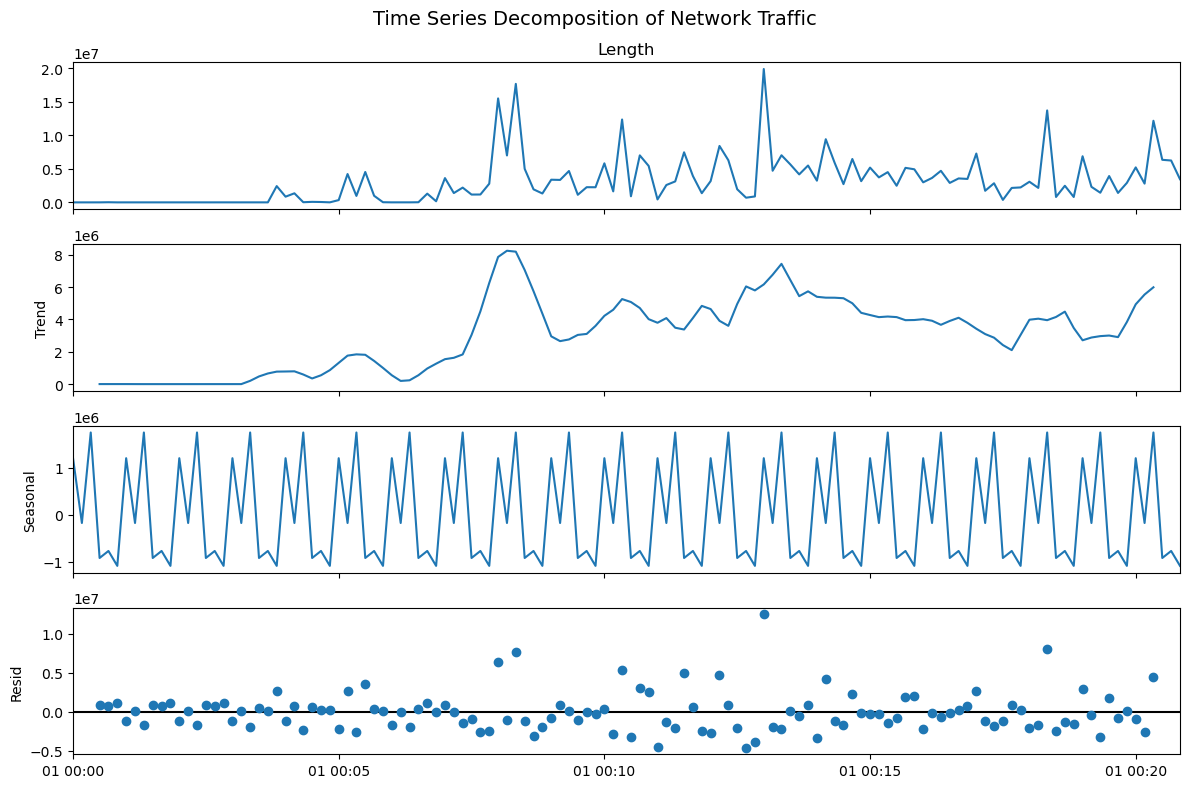

In [25]:
result.plot()
plt.gcf().set_size_inches(12, 8)

plt.suptitle(
    "Time Series Decomposition of Network Traffic",
    fontsize=14,
    y=0.98
)

plt.tight_layout()
plt.show()